# Generate app data

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from slabguide import Slab, Propagator, real_contour, ThreeJSMeshSaver, Plot3D

plt.style.use('dark_background')

In [15]:
A = Slab()

In [16]:
half_width = .6
shift = .35
amplitude = 1.

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

def quadratic_piecewise2d(x, zs=None, wavenumber=A.K0):
    fx = quadratic_piecewise(x)
    fz = np.exp(1j * wavenumber * zs)
    return np.outer(fz, fx)

f0 = quadratic_piecewise
F0 = quadratic_piecewise2d

In [17]:
P = Propagator(A, f0=f0, window=[Lx, Rx])

In [18]:
P.add_contour(real_contour(.0001, A.Z_evanescent, 150))
P.add_contour(real_contour(A.Z_evanescent, 10*A.Z_evanescent, 200))

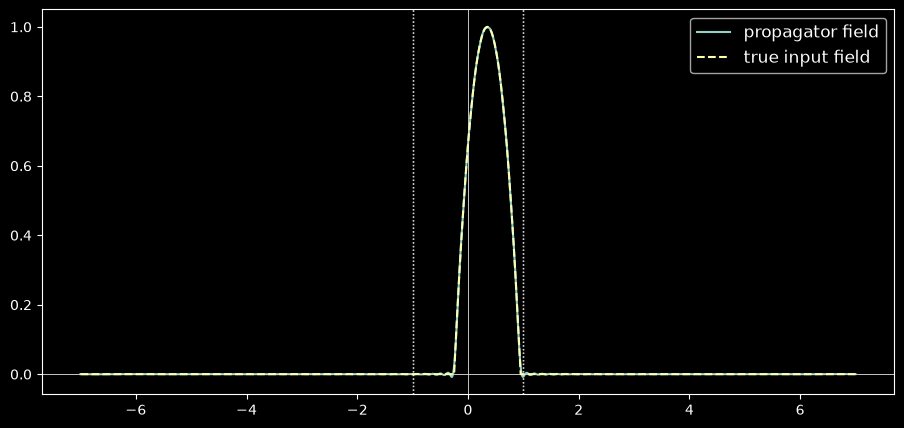

In [19]:
fig, ax = A.plot_field_1d(P, label='propagator field')
A.add_1d_plot(f0, ls='--', label='true input field');

In [20]:
xs = A.all_Xs[::6]
ys = np.linspace(0, 15, 450)
ymin, ymax = np.min(ys), np.max(ys)
Xs, Ys = np.meshgrid(xs, ys)
MS = ThreeJSMeshSaver(Xs, Ys)

trigs = MS.trig_indices
basepts = MS.base_vertices

Props = [P]

gs = np.array([Prop.Guided(xs,ys) for Prop in Props])
ps = np.array([Prop.Propagating(xs, ys) for Prop in Props])
evs = np.array([Prop.Evanescent(xs, ys) for Prop in Props])
f0s = np.array(Props[0].f0(xs), dtype=np.float32)
Nmesh = np.array(len(Props), dtype=np.uint32)

Rhos = A.Rhos

In [27]:
prefix='/home/pv/local/website/visualizations/basic/data/'

In [29]:
MS.save_trig_indices_as_json(prefix + 'trig_indices')
MS.save_base_vertices_as_json(prefix + 'base_vertices')


In [30]:
MS.save_values_as_json(prefix + 'f0s', f0s)
MS.save_values_as_json(prefix + 'x0s', xs)
MS.save_values_as_json(prefix + 'y0s', ys)
MS.save_values_as_json(prefix + 'Rhos', Rhos)


In [31]:
MS.save_heights_as_json_not_flat_complex(prefix + 'guided', gs, reduce_dims=False)


In [32]:
MS.save_heights_as_json_not_flat_complex(prefix + 'propagating', ps, reduce_dims=False)


In [33]:
MS.save_heights_as_json_not_flat_complex(prefix + 'evanescent', evs, reduce_dims=False)
